# Course 11: On-Device AI
## Session 3: Quantization I: integers instead of floats

**Goal:** quantize and dequantize tensors with scales and zero points, measure the error against the number of bits, quantize a trained MLP's weights per tensor and per channel, compare ways to calibrate activation ranges, and run the MLP with integer-only arithmetic in NumPy.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. Quantize and dequantize by hand
**Uniform affine quantization** maps a real number $x$ to an integer $q$ with a **scale** $s$ (the step between levels) and a **zero point** $z$ (the integer that stands for 0.0):

$$q = \text{clamp}\big(\text{round}(x / s) + z,\; q_{min},\; q_{max}\big), \qquad \hat x = s\,(q - z).$$

* **Asymmetric** (affine): the range $[\alpha, \beta]$ is mapped onto all $2^b$ levels, for example uint8 $0 \dots 255$: $s = (\beta - \alpha)/(2^b - 1)$, $z = \text{round}(-\alpha / s)$. The range is first widened to include 0, so that 0.0 (padding, ReLU outputs) is stored exactly.
* **Symmetric**: $z = 0$ and the range is $[-\max|x|, \max|x|]$, mapped onto $-(2^{b-1}-1) \dots 2^{b-1}-1$, for example int8 $-127 \dots 127$ or int4 $-7 \dots 7$. One level is wasted, but the arithmetic is simpler.

Inside the range, rounding moves each value by at most $s/2$. When values spread over many levels, the error is close to uniform on $[-s/2, s/2]$, so its mean square is about $s^2/12$. Values outside the range are **clipped**, which can cost much more.

**By hand first:** for $x = (-0.62, -0.1, 0, 0.31, 1.5)$ with 8-bit asymmetric quantization, compute $s$, $z$ and the integer for 0.31. Then run the cell.

In [1]:
import os
for _v in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[_v] = "1"                     # one BLAS thread for NumPy; set before NumPy is imported
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

torch.set_num_threads(1)
torch.manual_seed(0); np.random.seed(0)
t_start = time.time()

def qparams(lo, hi, bits, symmetric):
    if symmetric:
        qmax = 2 ** (bits - 1) - 1
        return max(abs(lo), abs(hi)) / qmax, 0, -qmax, qmax
    lo, hi = min(lo, 0.0), max(hi, 0.0)               # the range must contain 0
    qmax = 2 ** bits - 1
    s = (hi - lo) / qmax
    return s, int(round(-lo / s)), 0, qmax

def quantize(x, s, z, qmin, qmax):
    return np.clip(np.round(x / s) + z, qmin, qmax).astype(np.int64)

def dequantize(q, s, z):
    return s * (q - z)

x = np.array([-0.62, -0.1, 0.0, 0.31, 1.5])
for symmetric in [False, True]:
    s, z, qmin, qmax = qparams(x.min(), x.max(), 8, symmetric)
    q = quantize(x, s, z, qmin, qmax)
    print(f"{'symmetric ' if symmetric else 'asymmetric'} 8-bit: s = {s:.6f}, z = {z}, range of q {qmin}..{qmax}")
    print(f"   q = {q},  x_hat = {np.round(dequantize(q, s, z), 4)},  largest error {np.abs(dequantize(q, s, z) - x).max():.4f} (s/2 = {s / 2:.4f})")
print("integer ranges: int8 -128..127, uint8 0..255, int4 -8..7, uint4 0..15")

asymmetric 8-bit: s = 0.008314, z = 75, range of q 0..255
   q = [  0  63  75 112 255],  x_hat = [-0.6235 -0.0998  0.      0.3076  1.4965],  largest error 0.0035 (s/2 = 0.0042)
symmetric  8-bit: s = 0.011811, z = 0, range of q -127..127
   q = [-52  -8   0  26 127],  x_hat = [-0.6142 -0.0945  0.      0.3071  1.5   ],  largest error 0.0058 (s/2 = 0.0059)
integer ranges: int8 -128..127, uint8 0..255, int4 -8..7, uint4 0..15


### 2. Error against bits: Gaussian and heavy-tailed tensors
Each extra bit halves $s$, so the mean squared error falls 4 times: about 6 dB of **signal-to-quantization-noise ratio** (SQNR $= 10 \log_{10}(\text{signal variance} / \text{error variance})$) per bit. But the range is set by the largest value. We compare a Gaussian tensor with a **heavy-tailed** one (Student's t with 3 degrees of freedom, scaled to the same variance), whose rare large values stretch the range. Both have 100,000 values; quantization is symmetric with the min–max range, and then with the range clipped at the 99.9th percentile of $|x|$.

tensor                   | max|x| | bits | MSE       | s^2/12    | SQNR (dB) | SQNR, clipped at 99.9th percentile
Gaussian                 |   4.73 |    8 | 1.162e-04 | 1.157e-04 |      39.3 | 36.6
Gaussian                 |   4.73 |    7 | 4.694e-04 | 4.701e-04 |      33.3 | 34.1
Gaussian                 |   4.73 |    6 | 1.935e-03 | 1.942e-03 |      27.1 | 29.6
Gaussian                 |   4.73 |    5 | 8.276e-03 | 8.293e-03 |      20.8 | 23.8
Gaussian                 |   4.73 |    4 | 3.805e-02 | 3.808e-02 |      14.2 | 17.3
Gaussian                 |   4.73 |    3 | 2.084e-01 | 2.073e-01 |       6.8 | 10.0
Gaussian                 |   4.73 |    2 | 9.407e-01 | 1.866e+00 |       0.3 | 1.4
heavy-tailed (t, 3 dof)  |  43.48 |    8 | 9.714e-03 | 9.767e-03 |      20.1 | 12.8
heavy-tailed (t, 3 dof)  |  43.48 |    7 | 3.979e-02 | 3.969e-02 |      13.9 | 12.7
heavy-tailed (t, 3 dof)  |  43.48 |    6 | 1.525e-01 | 1.639e-01 |       8.1 | 12.5
heavy-tailed (t, 3 dof)  |  43.48 |    5 | 4.04

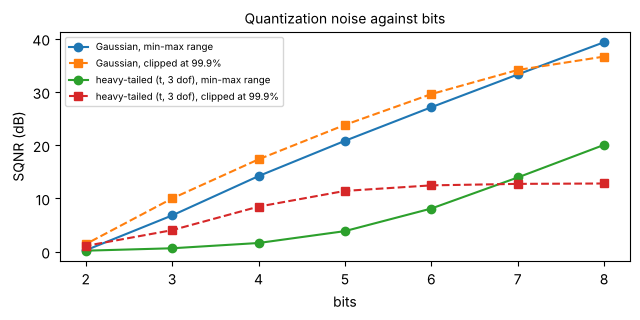

In [2]:
rng = np.random.default_rng(0)
tensors = {"Gaussian": rng.standard_normal(100_000),
           "heavy-tailed (t, 3 dof)": rng.standard_t(3, 100_000) / np.sqrt(3.0)}    # variance 1 for both

def fake_quant(x, bits, clip=None):
    amax = np.abs(x).max() if clip is None else clip
    s, z, qmin, qmax = qparams(-amax, amax, bits, True)
    return dequantize(quantize(x, s, z, qmin, qmax), s, z), s

bits_list = [8, 7, 6, 5, 4, 3, 2]
sqnr = {}
print(f"{'tensor':24s} | max|x| | bits | MSE       | s^2/12    | SQNR (dB) | SQNR, clipped at 99.9th percentile")
for name, t in tensors.items():
    sqnr[name] = ([], [])
    c999 = np.percentile(np.abs(t), 99.9)
    for b in bits_list:
        tq, s = fake_quant(t, b)
        tc, _ = fake_quant(t, b, clip=c999)
        mse, mse_c = np.mean((tq - t) ** 2), np.mean((tc - t) ** 2)
        sqnr[name][0].append(10 * np.log10(t.var() / mse)); sqnr[name][1].append(10 * np.log10(t.var() / mse_c))
        print(f"{name:24s} | {np.abs(t).max():6.2f} | {b:4d} | {mse:.3e} | {s * s / 12:.3e} | {sqnr[name][0][-1]:9.1f} | {sqnr[name][1][-1]:.1f}")

plt.figure(figsize=(6.5, 3.3))
for name, (full, clipped) in sqnr.items():
    plt.plot(bits_list, full, "o-", label=f"{name}, min-max range")
    plt.plot(bits_list, clipped, "s--", label=f"{name}, clipped at 99.9%")
plt.xlabel("bits"); plt.ylabel("SQNR (dB)"); plt.title("Quantization noise against bits", fontsize=10)
plt.legend(fontsize=7); plt.tight_layout(); plt.show()

### 3. A trained MLP: per-tensor against per-channel weight scales
We train an MLP (64 → 128 → 128 → 10) on the 8 × 8 digits (1,257 training and 540 test images) and quantize its **weights** symmetrically at 8, 6, 4, 3 and 2 bits, keeping activations and biases in float for now.

* **Per-tensor:** one scale for a whole weight matrix, set by its largest weight.
* **Per-channel:** one scale for each output channel (each row of the matrix), set by that row's largest weight. A row of small weights then gets a small step. The extra storage is one scale per row.

In [3]:
digits = load_digits()
X = (digits.data / 16.0).astype(np.float32)               # 1,797 x 64, pixel values 0..1
perm = np.random.default_rng(0).permutation(len(X))
tr, te = perm[:1257], perm[1257:]
Xtr, ytr, Xte, yte = X[tr], digits.target[tr], X[te], digits.target[te]

torch.manual_seed(0)
mlp = nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 10))
opt = torch.optim.Adam(mlp.parameters(), lr=1e-3)
g = torch.Generator().manual_seed(0)
Xt, yt = torch.tensor(Xtr), torch.tensor(ytr)
for epoch in range(60):
    order = torch.randperm(len(Xt), generator=g)
    for i in range(0, len(Xt), 64):
        b = order[i:i + 64]
        loss = F.cross_entropy(mlp(Xt[b]), yt[b])
        opt.zero_grad(); loss.backward(); opt.step()
W = [mlp[i].weight.detach().numpy().astype(np.float64) for i in (0, 2, 4)]
B = [mlp[i].bias.detach().numpy().astype(np.float64) for i in (0, 2, 4)]

def forward(x, Ws, Bs, act_q=None):
    h = x
    for i, (w, b) in enumerate(zip(Ws, Bs)):
        h = h @ w.T + b
        if i < len(Ws) - 1:
            h = np.maximum(h, 0)
            if act_q is not None:
                h = act_q[i](h)
    return h

def acc(logits):
    return float((logits.argmax(1) == yte).mean())

def quant_weight(w, bits, per_channel):
    qmax = 2 ** (bits - 1) - 1
    amax = np.abs(w).max(axis=1, keepdims=True) if per_channel else np.abs(w).max()
    s = amax / qmax
    return np.clip(np.round(w / s), -qmax, qmax) * s

acc_float = acc(forward(Xte, W, B))
print(f"float32 test accuracy: {acc_float:.3f}")
for i, w in enumerate(W):
    rows = np.abs(w).max(axis=1)
    print(f"layer {i + 1}: {w.shape[0]} rows; largest |weight| per row from {rows.min():.3f} to {rows.max():.3f} (median {np.median(rows):.3f})")
print(f"\n{'bits':>4s} | per-tensor accuracy | per-channel accuracy")
for bits in [8, 6, 4, 3, 2]:
    a_t = acc(forward(Xte, [quant_weight(w, bits, False) for w in W], B))
    a_c = acc(forward(Xte, [quant_weight(w, bits, True) for w in W], B))
    print(f"{bits:4d} | {a_t:19.3f} | {a_c:20.3f}")

float32 test accuracy: 0.976
layer 1: 128 rows; largest |weight| per row from 0.118 to 0.451 (median 0.291)
layer 2: 128 rows; largest |weight| per row from 0.088 to 0.505 (median 0.311)
layer 3: 10 rows; largest |weight| per row from 0.263 to 0.482 (median 0.338)

bits | per-tensor accuracy | per-channel accuracy
   8 |               0.976 |                0.976
   6 |               0.974 |                0.976
   4 |               0.978 |                0.976
   3 |               0.970 |                0.974
   2 |               0.087 |                0.752


### 4. Calibrating activation ranges
Weights are known before deployment; activations depend on the input. We run a **calibration set** (200 training images) through the model, record each hidden layer's ReLU outputs, and choose a clipping value $t$; the quantizer then uses $s = t / (2^b - 1)$ and $z = 0$ (ReLU outputs are never negative). Three common choices (Krishnamoorthi 2018; Nagel et al. 2021):

* **min–max:** $t$ = the largest value seen;
* **percentile:** $t$ = the 99.99th percentile;
* **MSE:** the $t$ that minimizes the mean squared quantization error on the calibration data (a simple grid search).

To show why this matters, we repeat the calibration with **one glitched image** added (all pixels multiplied by 10, like a sensor fault or a missed normalization step). Weights are int8 per-channel throughout; activations use 8, 4 or 3 bits.

In [4]:
W8 = [quant_weight(w, 8, True) for w in W]

def hidden(x, Ws=W8):
    acts, h = [], x
    for w, b in zip(Ws[:-1], B[:-1]):
        h = np.maximum(h @ w.T + b, 0); acts.append(h)
    return acts

def act_fq(t, bits):
    s = t / (2 ** bits - 1)
    return lambda h: np.clip(np.round(h / s), 0, 2 ** bits - 1) * s

def choose_t(a, method, bits):
    if method == "min-max":
        return a.max()
    if method == "percentile 99.99":
        return np.percentile(a, 99.99)
    grid = np.linspace(0.02, 1.0, 50) * a.max()                       # "MSE": search for the best clipping value
    errs = [np.mean((act_fq(t, bits)(a) - a) ** 2) for t in grid]
    return grid[int(np.argmin(errs))]

calib_clean = Xtr[:200]
calib_glitch = np.vstack([Xtr[:200], 10 * Xtr[200:201]])
test_acts = hidden(Xte)
print(f"{'calibration':21s} | {'method':16s} | bits | clipping t, layers 1 and 2 | test MSE, layer 1 | accuracy")
for cname, calib in [("200 images", calib_clean), ("200 images + glitch", calib_glitch)]:
    acts = hidden(calib)
    for bits in [8, 4, 3]:
        for method in ["min-max", "percentile 99.99", "MSE"]:
            ts = [choose_t(a, method, bits) for a in acts]
            fq = [act_fq(t, bits) for t in ts]
            mse1 = np.mean((fq[0](test_acts[0]) - test_acts[0]) ** 2)
            a = acc(forward(Xte, W8, B, act_q=fq))
            print(f"{cname:21s} | {method:16s} | {bits:4d} | {ts[0]:12.2f} {ts[1]:12.2f} | {mse1:17.2e} | {a:.3f}")

calibration           | method           | bits | clipping t, layers 1 and 2 | test MSE, layer 1 | accuracy
200 images            | min-max          |    8 |         2.68         7.33 |          7.78e-06 | 0.976
200 images            | percentile 99.99 |    8 |         2.46         7.16 |          6.93e-06 | 0.976
200 images            | MSE              |    8 |         2.62         7.18 |          7.46e-06 | 0.976
200 images            | min-max          |    4 |         2.68         7.33 |          2.25e-03 | 0.976
200 images            | percentile 99.99 |    4 |         2.46         7.16 |          1.90e-03 | 0.970
200 images            | MSE              |    4 |         1.93         5.86 |          1.34e-03 | 0.974
200 images            | min-max          |    3 |         2.68         7.33 |          1.04e-02 | 0.978
200 images            | percentile 99.99 |    3 |         2.46         7.16 |          8.75e-03 | 0.972
200 images            | MSE              |    3 |         1.

### 5. Integer-only inference
Jacob et al. (2018) showed how a phone can run the whole network in integers. For a layer $y = \text{ReLU}(Wx + b)$ with int8 weights $W \approx s_w q_w$ (per-channel $s_w$), uint8 inputs $x \approx s_x q_x$ and uint8 outputs $y \approx s_y q_y$:

1. **Accumulate in int32:** $\text{acc} = \sum_k q_w[c,k]\, q_x[k]$. Products of two 8-bit numbers need 16 bits, and sums of many of them need 32.
2. **Bias in int32**, at the accumulator's scale: $q_b = \text{round}(b / (s_w s_x))$.
3. **Requantize:** $q_y = \text{clamp}\big(\text{round}(M\,(\text{acc} + q_b)),\, 0,\, 255\big)$ with $M = s_w s_x / s_y$. The real number $M$ is stored as an integer $M_0$ and a shift, $M \approx M_0 \cdot 2^{-31-\text{shift}}$, so the device needs only an integer multiply and a bit shift.
4. **Fused ReLU:** clamping at 0 *is* the ReLU, so it costs nothing.

The last layer's outputs are requantized to int8 and the prediction is their argmax. Below, the input pixels use $s = 1/255$, and the activation scales come from the 8-bit percentile calibration of section 4.

In [5]:
def fixed_point(M):
    shift = np.floor(-np.log2(M)).astype(np.int64)                   # M * 2**shift lies in [0.5, 1)
    return np.round(M * 2.0 ** shift * 2 ** 31).astype(np.int64), shift

def requantize(acc32, M0, shift, lo, hi):
    total = 31 + shift
    return np.clip((acc32 * M0 + (np.int64(1) << (total - 1))) >> total, lo, hi)

acts_cal = hidden(calib_clean)
s_act = [1 / 255] + [np.percentile(a, 99.99) / 255 for a in acts_cal]   # input, hidden 1, hidden 2
s_out = np.abs(forward(calib_clean, W8, B)).max() / 127                   # int8 logits

layers = []
for i, (w, b) in enumerate(zip(W, B)):
    s_w = np.abs(w).max(axis=1) / 127                                       # per-channel int8 scales
    q_w = np.clip(np.round(w / s_w[:, None]), -127, 127).astype(np.int64)
    q_b = np.round(b / (s_w * s_act[i])).astype(np.int64)                  # int32 bias
    s_next = s_act[i + 1] if i < 2 else s_out
    M0, shift = fixed_point(s_w * s_act[i] / s_next)
    layers.append((q_w, q_b, M0, shift, (0, 255) if i < 2 else (-127, 127)))

def integer_forward(x):
    q = np.clip(np.round(x * 255), 0, 255).astype(np.int64)               # uint8 input
    worst = 0
    for q_w, q_b, M0, shift, (lo, hi) in layers:
        acc32 = q @ q_w.T + q_b
        worst = max(worst, int(np.abs(acc32).max()))
        q = requantize(acc32, M0, shift, lo, hi)                            # lo = 0 is the fused ReLU
    return q, worst

q_logits, worst = integer_forward(Xte)
pred_int = q_logits.argmax(1)
pred_float = forward(Xte, W, B).argmax(1)
print(f"largest |accumulator| {worst:,d}: fits in int32 (limit {2 ** 31 - 1:,d}): {worst < 2 ** 31}")
print(f"float32 accuracy {acc_float:.3f}; integer-only accuracy {float((pred_int == yte).mean()):.3f}; "
      f"same prediction as float on {float((pred_int == pred_float).mean()):.3f} of the test images")
print(f"example: requantization multipliers of layer 1 lie in [{(layers[0][2] / 2.0 ** (31 + layers[0][3])).min():.2e}, "
      f"{(layers[0][2] / 2.0 ** (31 + layers[0][3])).max():.2e}]")

t0 = time.perf_counter()
for _ in range(20):
    forward(Xte, W, B)
t_float = (time.perf_counter() - t0) / 20 * 1e3
t0 = time.perf_counter()
for _ in range(20):
    integer_forward(Xte)
t_int = (time.perf_counter() - t0) / 20 * 1e3
print(f"NumPy time for the 540 test images: float64 BLAS {t_float:.2f} ms, integer {t_int:.2f} ms (mean of 20 runs)")

largest |accumulator| 421,667: fits in int32 (limit 2,147,483,647): True
float32 accuracy 0.976; integer-only accuracy 0.974; same prediction as float on 0.998 of the test images
example: requantization multipliers of layer 1 lie in [3.78e-04, 1.44e-03]


NumPy time for the 540 test images: float64 BLAS 0.78 ms, integer 8.11 ms (mean of 20 runs)


### 6. Bytes saved
Model size counts everything that must be stored: the integer weights, plus one scale per channel (float32 here), plus the int32 biases. int4 weights are packed two per byte.

In [6]:
n_w = sum(w.size for w in W); n_b = sum(b.size for b in B); n_rows = sum(w.shape[0] for w in W)
sizes = {"float32 weights and biases": 4 * n_w + 4 * n_b,
         "int8 weights, per-tensor scales": n_w + 4 * len(W) + 4 * n_b,
         "int8 weights, per-channel scales": n_w + 4 * n_rows + 4 * n_b,
         "int4 weights (packed), per-channel scales": n_w // 2 + 4 * n_rows + 4 * n_b}
for k, v in sizes.items():
    print(f"{k:42s}: {v:7,d} bytes ({v / sizes['float32 weights and biases']:.3f} of float32)")
print(f"({n_w:,d} weights, {n_b} biases, {n_rows} output channels)")

float32 weights and biases                : 104,488 bytes (1.000 of float32)
int8 weights, per-tensor scales           :  26,932 bytes (0.258 of float32)
int8 weights, per-channel scales          :  27,984 bytes (0.268 of float32)
int4 weights (packed), per-channel scales :  15,056 bytes (0.144 of float32)
(25,856 weights, 266 biases, 266 output channels)


### 7. Exercises

In [7]:
# TODO: asymmetric per-channel weights. Quantize each row of each weight matrix with its own scale AND zero point
# (use qparams(row.min(), row.max(), bits, symmetric=False) with unsigned levels 0 .. 2**bits - 1), dequantize, and
# report the test accuracy at 4, 3 and 2 bits next to the symmetric per-channel results of section 3. When does the
# zero point help, and what does it cost in storage and in the integer matrix multiply?
def asymmetric_per_channel(bits):
    return None          # replace with the test accuracy

r = [asymmetric_per_channel(b) for b in (4, 3, 2)]
print("not done yet" if r[0] is None else r)

not done yet


In [8]:
# TODO: sweep the percentile used for 4-bit activations (for example 99, 99.9, 99.99 and 100) with the glitched
# calibration set, and plot test accuracy against the percentile. Which percentiles are safe here, and why?
def percentile_sweep():
    return None          # replace with a list of (percentile, accuracy)

r = percentile_sweep()
print("not done yet" if r is None else r)
print(f"runtime so far {time.time() - t_start:.0f} s")

not done yet
runtime so far 3 s


### What to notice
(Written from the saved run. Everything except the two NumPy timings in section 5 is the same on every run.)

1. **The hand example.** With 8-bit asymmetric quantization, $x = (-0.62, \dots, 1.5)$ gave $s = 0.008314$ and $z = 75$; 0.31 became 112 and came back as 0.3076. The largest error was 0.0035, below $s/2 = 0.0042$. The symmetric version needed a larger step ($s = 0.011811$), because it also reserves levels for values down to −1.5 that never occur.
2. **About 6 dB per bit, until the range is wrong.** For the Gaussian tensor the measured error matched $s^2/12$ to within 1% from 8 down to 3 bits, and the SQNR fell from 39.3 to 6.8 dB, about 6 dB per bit. At 2 bits the formula failed (0.94 against 1.87), because most values then fall into the zero level. The heavy-tailed tensor (largest value 43.48 against 4.73) reached only 20.1 dB at 8 bits, no better than a 5-bit Gaussian (20.8 dB). Clipping at the 99.9th percentile helped it at low bits (8.5 against 1.6 dB at 4 bits) but hurt at 8 bits (12.8 against 20.1 dB): the best range depends on the number of bits.
3. **Per-channel scales mattered only at the lowest bits here.** The float MLP scored 0.976. Down to 3 bits, both weight schemes stayed within 0.006 of it (3 bits: 0.970 per-tensor, 0.974 per-channel). At 2 bits per-tensor quantization collapsed to 0.087, chance level, while per-channel kept 0.752. The rows' largest weights differ by about 4 times within a layer (0.118 to 0.451 in layer 1), so one shared scale wastes levels on the small rows.
4. **One bad calibration image can ruin low-bit activations.** At 8 bits every calibration method gave 0.974–0.976, even with the glitched image. At 4 bits the glitch made min–max's activation error 62 times larger (2.25e-03 to 1.40e-01), yet accuracy only fell to 0.972: on this easy task the network tolerates coarse activations. At 3 bits the glitch was disastrous for min–max (0.178) and for the 99.99th percentile (0.830; with 201 calibration images the top 0.01% are still glitch values), while the MSE search kept 0.961. One test image is worth 0.0019, so differences below about 0.01 are a few images and mean little.
5. **Integer-only inference works.** With int8 weights, uint8 activations, int32 biases and accumulators, fixed-point requantization and fused ReLU, the integer model scored 0.974 against 0.976 and agreed with the float model on 0.998 of the test images (all but one). The largest accumulator was 421,667, far below the int32 limit, and the requantization multipliers of layer 1 (3.78e-04 to 1.44e-03) were stored as 31-bit integers and shifts.
6. **Against expectation for speed: integers were slower here.** NumPy's integer forward pass took 8.11 ms against 0.78 ms for the float pass, about 10 times slower, because NumPy has no optimized integer matrix multiply while its float path calls BLAS. Integers save time only when the runtime has int8 kernels that use the CPU's integer dot-product instructions; session 4 times such a kernel.
7. **Bytes.** The float32 model is 104,488 bytes; int8 weights with per-channel scales take 27,984 bytes (0.268) and packed int4 weights 15,056 bytes (0.144). The ratios are not exactly 1/4 and 1/8, because the scales and the int32 biases also take space; in a small model that overhead shows.